# 四层探测器缪子散射成像：PoCA 基线 Notebook

这是本项目的**学习版分析 Notebook**。它从 Geant4 导出的 `muon_tracks.csv` 出发，依次完成：

1. 检查四层探测器击中数据；
2. 理解散射角与 PoCA 点；
3. 将 PoCA 点累积成固定体素图像；
4. 在不同事件数下计算 IoU 和定位误差。

建议严格从上到下逐格运行。每个代码单元前都说明了“为什么需要这一步”。

## 0. 这份数据在物理上表示什么

Geant4 中有四个平面探测器：上游两层用于拟合**入射轨迹**，下游两层用于拟合**出射轨迹**。缪子穿过 U 型铝目标后会发生多重库仑散射，因此两条直线会有一个小夹角。

PoCA（Point of Closest Approach）把两条直线最近点连线的中点，近似为该缪子主要发生散射的位置。这个近似并不完美，但简单、可解释，适合做第一条基线。

In [46]:
# 导入本 Notebook 需要的库。
# pandas：读取和整理 CSV；numpy：数值计算；matplotlib：绘图。
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 让图中的中文在大多数 macOS 环境里更容易显示。
plt.rcParams['font.sans-serif'] = ['PingFang SC', 'Heiti SC', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# Notebook 位于 muon_analysis 文件夹，因此 CSV 默认就在同一目录。
DATA_PATH = Path('muon_tracks.csv')
print('准备读取：', DATA_PATH.resolve())

准备读取： /Users/xuyaoyang/geant4-test/muon_analysis/muon_tracks.csv


## 1. 读取 CSV，并先确认数据是否完整

这一格不做任何成像。先查看列名和前几行，确认 Geant4 输出中确实包含四层击中、PoCA 坐标和散射角。这样若后面报错，能更快判断是数据问题还是算法问题。

In [47]:
# 读取 Geant4 输出。每一行对应一条通过四层探测器的完整缪子径迹。
df = pd.read_csv(DATA_PATH)

print(f'完整径迹数：{len(df):,}')
print('\nCSV 字段：')
print(df.columns.tolist())
display(df.head())

完整径迹数：9,975

CSV 字段：
['event', 'up1_x_mm', 'up1_y_mm', 'up1_z_mm', 'up2_x_mm', 'up2_y_mm', 'up2_z_mm', 'down1_x_mm', 'down1_y_mm', 'down1_z_mm', 'down2_x_mm', 'down2_y_mm', 'down2_z_mm', 'poca_x_mm', 'poca_y_mm', 'poca_z_mm', 'theta_x_mrad', 'theta_y_mrad', 'theta_mrad']


,event,up1_x_mm,up1_y_mm,up1_z_mm,up2_x_mm,up2_y_mm,up2_z_mm,down1_x_mm,down1_y_mm,down1_z_mm,down2_x_mm,down2_y_mm,down2_z_mm,poca_x_mm,poca_y_mm,poca_z_mm,theta_x_mrad,theta_y_mrad,theta_mrad
0,0,-110.8530,35.32500,-405,-110.8890,35.28940,-305,-111.0080,35.11960,295,-111.0400,35.11940,395,-111.0050,35.1248,143.9500,0.036531,0.353843,0.355724
1,1,139.8240,111.57700,-405,139.8520,111.52700,-305,139.8900,111.36100,295,139.9050,111.32700,395,139.7530,111.6820,-630.3210,-0.123838,0.156143,0.199290
2,2,-15.3030,47.05700,-405,-15.2627,47.04200,-305,-14.8524,46.91880,295,-14.7597,46.94070,395,-15.0604,46.9292,109.2800,0.525042,0.368033,0.641184
3,3,-143.9370,77.24070,-405,-143.9910,77.19090,-305,-144.0890,77.02930,295,-144.0550,76.99320,395,-144.1750,77.0772,23.5229,0.880683,0.137576,0.891363
4,4,37.0839,8.19737,-405,37.1205,8.24551,-305,37.0023,9.26933,295,36.9045,9.50702,395,37.2759,8.4129,-47.1158,-1.344200,1.895550,2.323780


### 字段速查

- `up1_*`、`up2_*`：上游两层的击中坐标；
- `down1_*`、`down2_*`：下游两层的击中坐标；
- `poca_*`：在 C++ 端由两条拟合直线计算的 PoCA 坐标；
- `theta_x_mrad`、`theta_y_mrad`：x-z 和 y-z 平面上的投影散射角；
- `theta_mrad`：总散射角，后面用它的平方作为体素权重。

坐标单位是 mm，角度单位是 mrad。

In [48]:
# 如果下面缺少任何字段，说明当前 CSV 不是本项目需要的完整输出格式。
REQUIRED_COLUMNS = {
    'up1_x_mm', 'up1_y_mm', 'up1_z_mm',
    'up2_x_mm', 'up2_y_mm', 'up2_z_mm',
    'down1_x_mm', 'down1_y_mm', 'down1_z_mm',
    'down2_x_mm', 'down2_y_mm', 'down2_z_mm',
    'poca_x_mm', 'poca_y_mm', 'poca_z_mm', 'theta_mrad',
}
missing = REQUIRED_COLUMNS - set(df.columns)
assert not missing, f'CSV 缺少字段：{sorted(missing)}'
print('✓ CSV 字段检查通过。')

✓ CSV 字段检查通过。


## 2. 看一眼上下游击中位置

理想入射模式下，探测器平面上的击中分布接近均匀；这张图本身不直接显示 U 型目标。真正携带目标信息的是上下游轨迹之间的变化，即散射角和 PoCA 点。

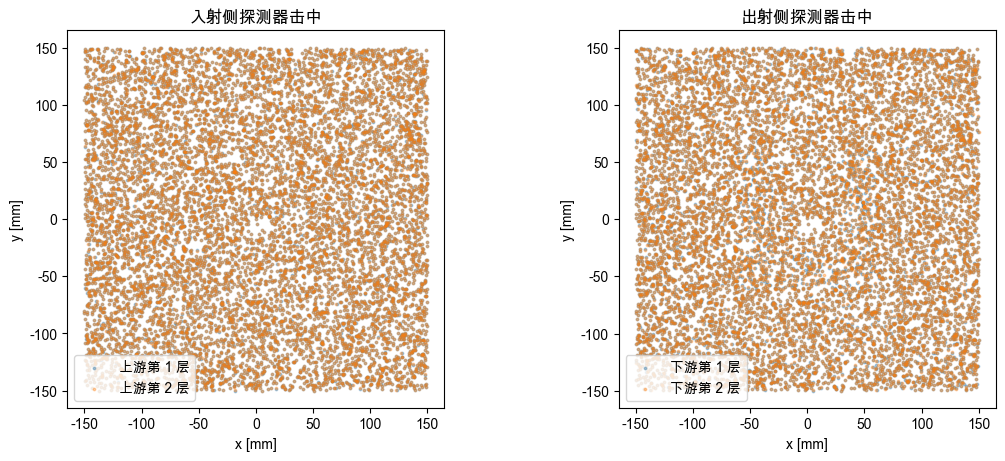

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)

# 上游：缪子进入目标前的两次位置测量。
axes[0].scatter(df['up1_x_mm'], df['up1_y_mm'], s=3, alpha=0.35, label='上游第 1 层')
axes[0].scatter(df['up2_x_mm'], df['up2_y_mm'], s=3, alpha=0.35, label='上游第 2 层')
axes[0].set(title='入射侧探测器击中', xlabel='x [mm]', ylabel='y [mm]')
axes[0].set_aspect('equal')
axes[0].legend()

# 下游：缪子穿过目标后的两次位置测量。
axes[1].scatter(df['down1_x_mm'], df['down1_y_mm'], s=3, alpha=0.35, label='下游第 1 层')
axes[1].scatter(df['down2_x_mm'], df['down2_y_mm'], s=3, alpha=0.35, label='下游第 2 层')
axes[1].set(title='出射侧探测器击中', xlabel='x [mm]', ylabel='y [mm]')
axes[1].set_aspect('equal')
axes[1].legend()
plt.show()

## 3. 散射角分布

`theta_mrad` 越大，通常意味着缪子在目标附近经历了更明显的散射。后续固定体素 PoCA 不只是计数，而是累加 $\theta^2$，从而使大散射事件对图像贡献更大。

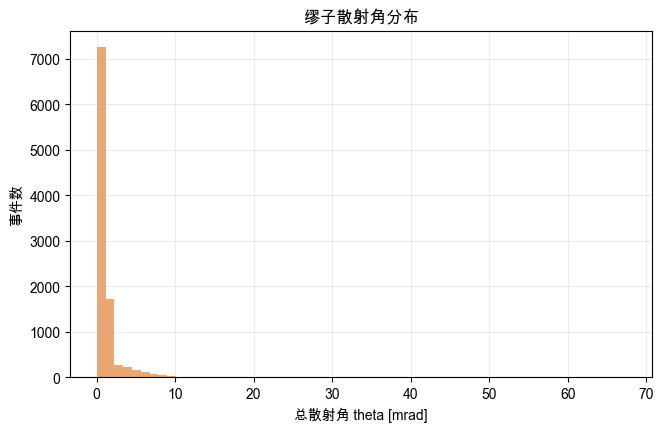

count    9975.000000
mean        1.205232
std         1.699581
min         0.003353
25%         0.486866
50%         0.780169
75%         1.178480
max        67.309300
Name: theta_mrad, dtype: float64


In [50]:
plt.figure(figsize=(7.5, 4.5))
plt.hist(df['theta_mrad'], bins=60, histtype='stepfilled', alpha=0.55, color='#d95f02')
plt.xlabel('总散射角 theta [mrad]')
plt.ylabel('事件数')
plt.title('缪子散射角分布')
plt.grid(alpha=0.25)
plt.show()

print(df['theta_mrad'].describe())

## 4. 先观察 PoCA 三维点云

颜色表示散射角。三维点云适合帮助你建立直觉，但论文中通常还需要体素图，因为体素图可以稳定地计算轮廓、IoU 和定位误差。

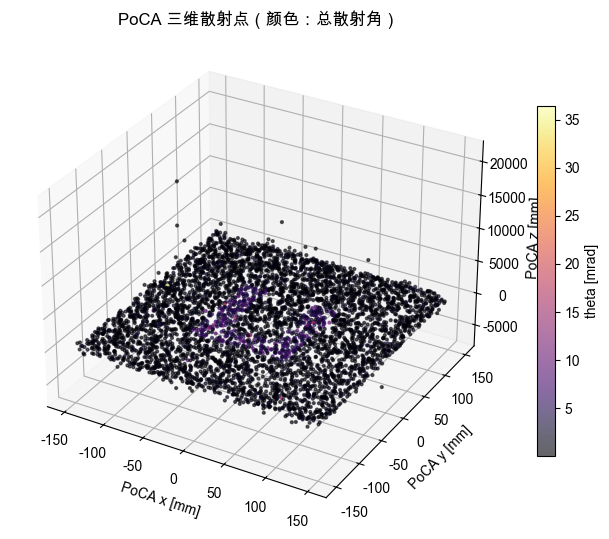

In [51]:
fig = plt.figure(figsize=(8, 6.5))
ax = fig.add_subplot(111, projection='3d')

# 使用少量点可以让三维图更清晰；若数据更少则直接使用全部。
plot_df = df.sample(min(5000, len(df)), random_state=20260921)
scatter = ax.scatter(
    plot_df['poca_x_mm'], plot_df['poca_y_mm'], plot_df['poca_z_mm'],
    c=plot_df['theta_mrad'], s=4, alpha=0.6, cmap='inferno'
)
ax.set(xlabel='PoCA x [mm]', ylabel='PoCA y [mm]', zlabel='PoCA z [mm]',
       title='PoCA 三维散射点（颜色：总散射角）')
fig.colorbar(scatter, ax=ax, shrink=0.7, label='theta [mrad]')
plt.show()

## 5. 设定固定体素 PoCA 的参数

这些参数就是你之后做改进算法时必须固定的**基线条件**。先不要随意改动；改参数应该单独成为一组实验，并记录到论文和 Git 提交中。

In [52]:
# 成像区域覆盖 U 型目标（目标在 xy 平面约为 ±60 mm）。
XY_LIMIT_MM = 90.0
Z_LIMIT_MM = 100.0

# 32³ 是当前论文基线网格。增大 BINS 会得到更细图像，
# 但在低统计量下也会让每个体素更稀疏、更噪。
BINS = 32

# 体素权重：每个体素累加 theta_mrad²。
WEIGHT_DESCRIPTION = 'sum(theta_mrad²)'

print(f'成像范围：x/y ±{XY_LIMIT_MM:g} mm，z ±{Z_LIMIT_MM:g} mm')
print(f'体素网格：{BINS} × {BINS} × {BINS}')
print(f'体素权重：{WEIGHT_DESCRIPTION}')

成像范围：x/y ±90 mm，z ±100 mm
体素网格：32 × 32 × 32
体素权重：sum(theta_mrad²)


## 6. 将 PoCA 点累积到三维体素

函数做三件事：

1. 去掉成像范围外的 PoCA 点；
2. 用 `numpy.histogramdd` 把三维空间分成规则体素；
3. 在每个体素中累加 $\theta^2$。

注意：函数不修改原始 `df`，因此每次实验都可以从同一份 Geant4 数据公平比较。

In [53]:
def voxelize_poca(data: pd.DataFrame, bins: int = BINS,
                  xy_limit: float = XY_LIMIT_MM,
                  z_limit: float = Z_LIMIT_MM):
    """把 PoCA 事件变成固定网格的三维散射强度。

    参数
    ----
    data : 需要重建的事件子集。
    bins : x、y、z 三个方向使用的体素数。
    xy_limit, z_limit : 成像范围半宽，单位 mm。

    返回
    ----
    volume : shape=(bins, bins, bins) 的体素强度数组。
    edges : 三个方向的体素边界。
    valid : 实际落入成像范围的事件。它用于统计，而非修改输入数据。
    """
    # 仅保留落入重建区域的 PoCA 点；范围外的点不参与体素累积。
    valid = data[
        (data['poca_x_mm'].abs() <= xy_limit)
        & (data['poca_y_mm'].abs() <= xy_limit)
        & (data['poca_z_mm'].abs() <= z_limit)
    ].copy()

    # histogramdd 需要每个方向的分箱边界，而不是体素中心。
    edges = [
        np.linspace(-xy_limit, xy_limit, bins + 1),
        np.linspace(-xy_limit, xy_limit, bins + 1),
        np.linspace(-z_limit, z_limit, bins + 1),
    ]

    # theta² 让高散射事件比近似直行事件拥有更大权重。
    weights = valid['theta_mrad'].to_numpy() ** 2
    volume, edges = np.histogramdd(
        valid[['poca_x_mm', 'poca_y_mm', 'poca_z_mm']].to_numpy(),
        bins=edges,
        weights=weights,
    )
    return volume, edges, valid


volume, voxel_edges, valid_events = voxelize_poca(df)
print(f'进入成像范围的 PoCA 点：{len(valid_events):,} / {len(df):,}')
print('体素数组形状：', volume.shape)

进入成像范围的 PoCA 点：1,649 / 9,975
体素数组形状： (32, 32, 32)


## 7. 得到最基础的 U 型目标 XY 图像

这里沿 z 方向把三维体素强度相加，得到 xy 投影。你应该能看到开口朝 +y 的 U 型大致轮廓。若看不到，先检查：是否运行了 Geant4、是否使用正确 CSV、成像范围是否仍覆盖目标。

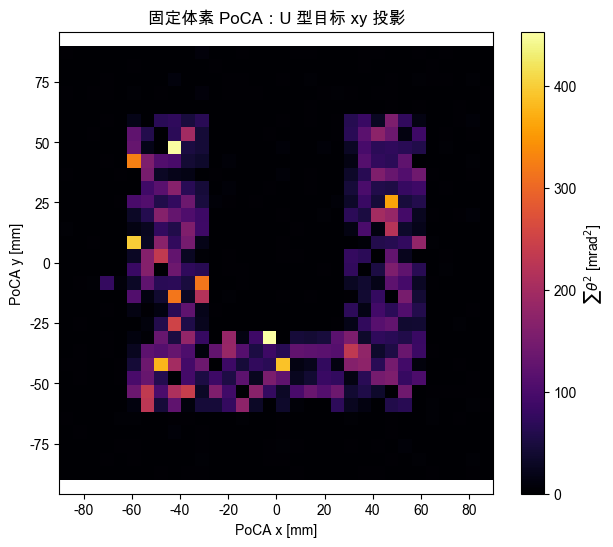

In [54]:
# axis=2 对应 z 方向；求和后留下 x-y 平面强度图。
xy_image = volume.sum(axis=2)

plt.figure(figsize=(7, 6))
mesh = plt.pcolormesh(
    voxel_edges[0], voxel_edges[1], xy_image.T,
    shading='auto', cmap='inferno'
)
plt.colorbar(mesh, label=r'$\sum \theta^2$ [mrad$^2$]')
plt.xlabel('PoCA x [mm]')
plt.ylabel('PoCA y [mm]')
plt.title('固定体素 PoCA：U 型目标 xy 投影')
plt.axis('equal')
plt.show()

## 8. 构造 U 型真值掩膜，并定义评价指标

IoU 需要真实目标轮廓。这里的真值掩膜严格对应 Geant4 中的 U 型铝目标：外尺寸 120 mm × 120 mm、壁厚 30 mm、开口朝 +y。

为了不让不同事件数各自“挑选最有利阈值”，采用**等面积 Top-k**：预测图中取强度最高的 k 个像素，且 k 固定为真值掩膜的像素数。

In [55]:
def u_target_mask(x_centers: np.ndarray, y_centers: np.ndarray) -> np.ndarray:
    """返回与 DetectorConstruction.cc 一致的 U 型二维真值掩膜。"""
    x_grid, y_grid = np.meshgrid(x_centers, y_centers, indexing='ij')

    # U 的底边：y 从 -60 到 -30 mm。
    bottom = (np.abs(x_grid) <= 60.0) & (y_grid >= -60.0) & (y_grid <= -30.0)
    # 左、右竖边：x 分别位于 [-60, -30] 与 [30, 60] mm。
    left = (x_grid >= -60.0) & (x_grid <= -30.0) & (y_grid >= -30.0) & (y_grid <= 60.0)
    right = (x_grid >= 30.0) & (x_grid <= 60.0) & (y_grid >= -30.0) & (y_grid <= 60.0)
    return bottom | left | right


def evaluate_xy_image(image: np.ndarray, x_centers: np.ndarray, y_centers: np.ndarray):
    """计算等面积 IoU 和散射强度质心定位误差。"""
    truth = u_target_mask(x_centers, y_centers)
    k = int(truth.sum())

    # 强度最高的 k 个体素像素视为重建得到的目标区域。
    predicted = np.zeros_like(truth, dtype=bool)
    top_indices = np.argpartition(image.ravel(), -k)[-k:]
    predicted.ravel()[top_indices] = True

    intersection = np.logical_and(predicted, truth).sum()
    union = np.logical_or(predicted, truth).sum()
    iou = intersection / union if union else np.nan

    # 强度加权质心与真值掩膜几何中心的距离定义为定位误差。
    x_grid, y_grid = np.meshgrid(x_centers, y_centers, indexing='ij')
    total = image.sum()
    rec_x = (image * x_grid).sum() / total
    rec_y = (image * y_grid).sum() / total
    true_x, true_y = x_grid[truth].mean(), y_grid[truth].mean()
    localization_error_mm = np.hypot(rec_x - true_x, rec_y - true_y)
    return iou, localization_error_mm, truth, predicted


x_centers = (voxel_edges[0][:-1] + voxel_edges[0][1:]) / 2
y_centers = (voxel_edges[1][:-1] + voxel_edges[1][1:]) / 2
iou, loc_error, truth_mask, predicted_mask = evaluate_xy_image(xy_image, x_centers, y_centers)
print(f'全部事件基线 IoU：{iou:.4f}')
print(f'全部事件定位误差：{loc_error:.4f} mm')

全部事件基线 IoU：0.8409
全部事件定位误差：3.8045 mm


## 9. 低统计量：只改变事件数，其他条件保持不变

这一步是论文的基线实验。每个事件数重复随机抽样多次，报告均值和标准差，避免一次抽样的偶然性被误认为算法效果。这里使用与已完成基线实验一致的随机种子和事件数。

In [56]:
EVENT_COUNTS = [1000, 3000, 5000]
REPEATS = 5
RANDOM_SEED = 20260921

rng = np.random.default_rng(RANDOM_SEED)
records = []

for n_events in EVENT_COUNTS:
    for repeat in range(REPEATS):
        # 无放回抽样：同一次重建中同一条缪子事件不会被重复使用。
        subset = df.iloc[rng.choice(len(df), size=n_events, replace=False)]
        sub_volume, sub_edges, sub_valid = voxelize_poca(subset)
        sub_image = sub_volume.sum(axis=2)
        sub_iou, sub_error, _, _ = evaluate_xy_image(sub_image, x_centers, y_centers)
        records.append({
            'event_count': n_events,
            'repeat': repeat + 1,
            'poca_points_in_volume': len(sub_valid),
            'iou': sub_iou,
            'localization_error_mm': sub_error,
        })

results = pd.DataFrame(records)
summary = results.groupby('event_count').agg(
    repeats=('repeat', 'count'),
    iou_mean=('iou', 'mean'), iou_std=('iou', 'std'),
    error_mean=('localization_error_mm', 'mean'),
    error_std=('localization_error_mm', 'std'),
).reset_index()
display(summary)

,event_count,repeats,iou_mean,iou_std,error_mean,error_std
0,1000,5,0.283577,0.025626,9.464461,6.045081
1,3000,5,0.380200,0.022851,7.129148,4.772667
2,5000,5,0.591559,0.020192,4.363651,1.515423


## 10. 画出事件数与图像质量的关系

理想情况下，事件数增加时 IoU 上升、定位误差下降。若你在改动算法后重新运行这部分，就能和固定体素 PoCA 基线进行公平对比。

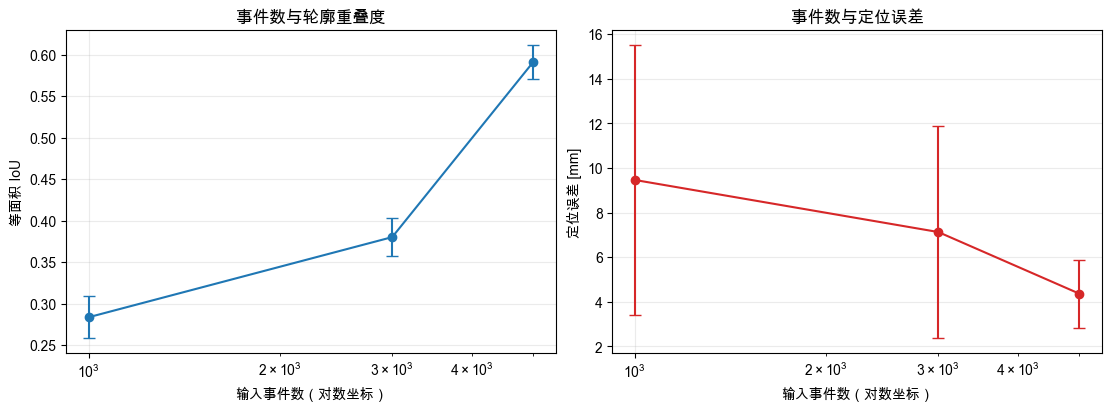

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

axes[0].errorbar(summary['event_count'], summary['iou_mean'], yerr=summary['iou_std'],
                 marker='o', capsize=4, color='#1f77b4')
axes[0].set_xscale('log')
axes[0].set(xlabel='输入事件数（对数坐标）', ylabel='等面积 IoU', title='事件数与轮廓重叠度')
axes[0].grid(alpha=0.25)

axes[1].errorbar(summary['event_count'], summary['error_mean'], yerr=summary['error_std'],
                 marker='o', capsize=4, color='#d62728')
axes[1].set_xscale('log')
axes[1].set(xlabel='输入事件数（对数坐标）', ylabel='定位误差 [mm]', title='事件数与定位误差')
axes[1].grid(alpha=0.25)
plt.show()

## 11. 下一步要做什么

你现在已经完成了传统固定体素 PoCA 的学习和复现实验。下一步是**散射角筛选 POCA**：

1. 在重建前加一条 `theta_mrad >= threshold` 的筛选；
2. 扫描多个阈值，而不是凭图像主观选择；
3. 对每个阈值重复本 Notebook 的低统计量实验；
4. 与这里的 IoU、定位误差和运行时间比较；
5. 将最优参数、随机种子、图和表写进论文第 6、7 章，并提交 GitHub。

**重要原则：** 每次只改变一个核心变量。否则即使图像变好，也无法说明真正起作用的是哪一个改动。

## 12. 散射角筛选：筛掉哪些事件？

散射角筛选只改变事件集合，不改变 PoCA、体素大小或 `theta²` 权重。对于给定的入射事件子集，保留 `theta_mrad >= theta_min_mrad` 的事件。`theta_min_mrad = 0` 就是没有筛选的基线。

注意：阈值不是越大越好。阈值提高会减少小角散射背景，但也会丢掉有效事件；必须看 IoU、定位误差和保留比例三者的平衡。

In [ ]:
def filter_by_scattering_angle(events: pd.DataFrame, theta_min_mrad: float) -> pd.DataFrame:
    """保留散射角不小于阈值的事件，不修改原始 DataFrame。"""
    return events.loc[events['theta_mrad'] >= theta_min_mrad].copy()

# 第一轮阈值扫描。0 mrad 是固定体素 PoCA 基线。
ANGLE_THRESHOLDS_MRAD = [0.0, 0.5, 1.0, 2.0, 4.0, 6.0]

## 13. 读取正式阈值扫描结果

正式实验由 `run_angle_filter_experiment.py` 完成：对 1000、3000、5000 个入射事件各随机重复 5 次，并保证同一次抽样下每个阈值使用完全相同的入射事件。下面读取输出结果，而不是在 Notebook 中重新做一遍大量循环。

In [58]:
RESULTS_PATH = Path('angle_filter_results/angle_filter_metrics_summary.csv')
angle_summary = pd.read_csv(RESULTS_PATH)
angle_summary[['event_count', 'theta_min_mrad', 'retention_ratio_mean',
               'iou_mean', 'localization_error_mm_mean']]

,event_count,theta_min_mrad,retention_ratio_mean,iou_mean,localization_error_mm_mean
0,1000,0.0,1.000000,0.283577,9.464461
1,1000,0.5,0.735800,0.280104,9.464031
2,1000,1.0,0.332600,0.287685,9.559877
3,1000,2.0,0.108600,0.281768,9.736179
4,1000,4.0,0.059200,0.251606,11.614781
5,1000,6.0,0.026000,0.208530,16.383035
6,3000,0.0,1.000000,0.380200,7.129148
7,3000,0.5,0.735467,0.380200,7.125207
8,3000,1.0,0.341867,0.425316,7.135979
9,3000,2.0,0.109733,0.456389,7.318041


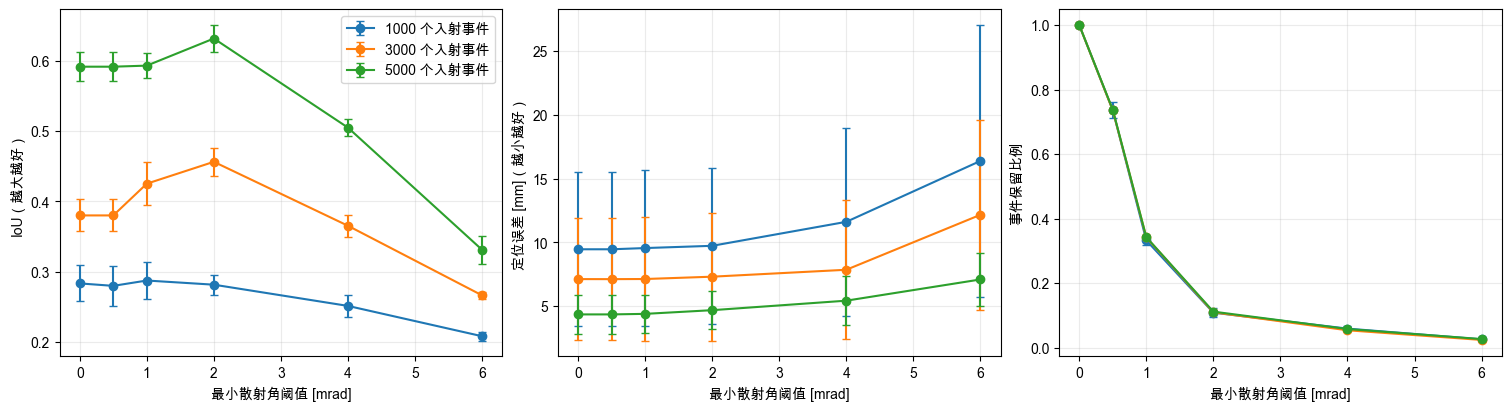

In [59]:
# 同一输入事件数下，分别查看轮廓质量、定位精度与事件保留比例。
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
plots = [
    ('iou_mean', 'iou_std', 'IoU（越大越好）'),
    ('localization_error_mm_mean', 'localization_error_mm_std', '定位误差 [mm]（越小越好）'),
    ('retention_ratio_mean', 'retention_ratio_std', '事件保留比例'),
]
for ax, (mean_col, std_col, ylabel) in zip(axes, plots):
    for event_count, group in angle_summary.groupby('event_count'):
        ax.errorbar(group['theta_min_mrad'], group[mean_col], yerr=group[std_col],
                    marker='o', capsize=3, label=f'{event_count} 个入射事件')
    ax.set(xlabel='最小散射角阈值 [mrad]', ylabel=ylabel)
    ax.grid(alpha=0.25)
axes[0].legend()
plt.show()

## 14. 如何解释这一轮结果

本轮理想源 U 型铝目标实验中，`2 mrad` 在 3000 和 5000 个入射事件下提升了 IoU，但定位误差没有同步改善；`4–6 mrad` 筛选过严，保留事件过少，轮廓和定位都变差。

因此当前可得出的结论是：**中等强度的散射角筛选有改善轮廓恢复的潜力，但尚不能宣称整体成像性能全面提升。** 下一步需要将 `1–3 mrad` 附近作为候选范围，结合散射角截断加权和自适应体素进一步验证。

## 15. 散射角截断加权：为什么要限制极端大角度事件？

PoCA 基线使用 `theta_mrad²` 作为体素权重。它能突出明显散射，但极端大散射角事件也可能让少数体素异常明亮、拉偏强度质心。截断加权保持事件位置不变，仅将权重改为：

`w_i = min(theta_i², theta_cap²)`

本实验固定 `theta >= 2 mrad`，扫描不同 `theta_cap`，检查是否能同时改善轮廓和定位。

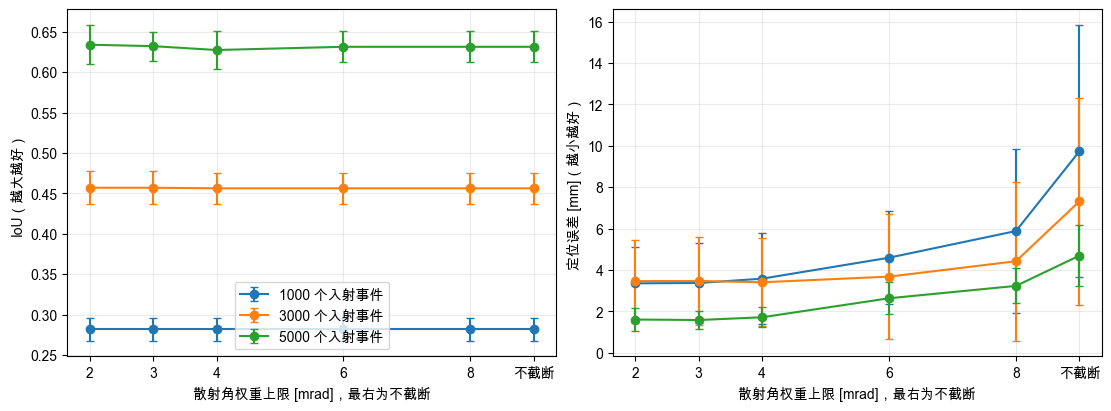

In [60]:
WEIGHTING_RESULTS_PATH = Path('angle_weighting_results/angle_weighting_metrics_summary.csv')
weighting_summary = pd.read_csv(WEIGHTING_RESULTS_PATH)

# 只画 theta >= 2 mrad 的截断加权方案；基线仍保留在 CSV 中。
plot_data = weighting_summary[weighting_summary['theta_min_mrad'] == 2.0].copy()
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for event_count, group in plot_data.groupby('event_count'):
    group = group.sort_values('cap_display_mrad')
    axes[0].errorbar(group['cap_display_mrad'], group['iou_mean'], yerr=group['iou_std'],
                     marker='o', capsize=3, label=f'{event_count} 个入射事件')
    axes[1].errorbar(group['cap_display_mrad'], group['localization_error_mm_mean'],
                     yerr=group['localization_error_mm_std'], marker='o', capsize=3,
                     label=f'{event_count} 个入射事件')
for ax, ylabel in zip(axes, ['IoU（越大越好）', '定位误差 [mm]（越小越好）']):
    ax.set(xlabel='散射角权重上限 [mrad]，最右为不截断', ylabel=ylabel)
    ax.set_xticks([2, 3, 4, 6, 8, 9])
    ax.set_xticklabels(['2', '3', '4', '6', '8', '不截断'])
    ax.grid(alpha=0.25)
axes[0].legend()
plt.show()

## 16. 本轮可得出的结论

截断加权明显降低了定位误差。以 5000 个入射事件为例：未筛选基线的定位误差为 `4.36 mm`；使用 `theta >= 2 mrad` 且 `theta_cap = 3 mrad` 后，定位误差降至 `1.59 mm`，IoU 由 `0.592` 提升至 `0.632`。

在 3000 个入射事件下，`2–4 mrad` 截断上限的 IoU 约为 `0.456–0.457`，定位误差约为 `3.4 mm`，优于未截断的仅筛选结果。当前可以把“散射角筛选 + 截断加权”保留为下一阶段自适应体素的对照方法；但仍需在目标位置、尺寸和探测器误差变化后验证泛化性。

## 17. 自适应体素：让分辨率随局部统计量变化

固定 32³ 体素在低统计量时容易出现大量空体素。自适应体素先用 16³ 粗网格进行统计，再按照散射加权强度选择高信息区域细分为 2×2×2 子体素。

细分规则只使用 PoCA 事件和截断散射角权重，**不使用 U 型真值掩膜**；真值只在最后计算 IoU 和定位误差时使用。

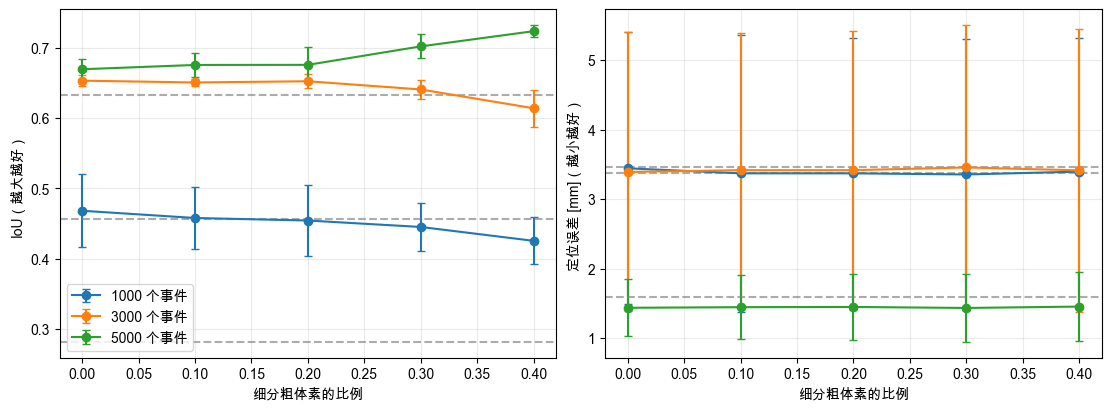

In [61]:
ADAPTIVE_RESULTS_PATH = Path('adaptive_voxel_results/adaptive_voxel_metrics_summary.csv')
FIXED_REFERENCE_PATH = Path('adaptive_voxel_results/adaptive_voxel_fixed_reference.csv')
adaptive_summary = pd.read_csv(ADAPTIVE_RESULTS_PATH)
fixed_reference = pd.read_csv(FIXED_REFERENCE_PATH)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for event_count, group in adaptive_summary.groupby('event_count'):
    axes[0].errorbar(group['refine_fraction'], group['iou_mean'], yerr=group['iou_std'],
                     marker='o', capsize=3, label=f'{event_count} 个事件')
    axes[1].errorbar(group['refine_fraction'], group['localization_error_mm_mean'],
                     yerr=group['localization_error_mm_std'], marker='o', capsize=3,
                     label=f'{event_count} 个事件')
    baseline = fixed_reference[fixed_reference['event_count'] == event_count].iloc[0]
    axes[0].axhline(baseline['iou_mean'], color='gray', linestyle='--', alpha=0.65)
    axes[1].axhline(baseline['localization_error_mm_mean'], color='gray', linestyle='--', alpha=0.65)
axes[0].set(xlabel='细分粗体素的比例', ylabel='IoU（越大越好）')
axes[1].set(xlabel='细分粗体素的比例', ylabel='定位误差 [mm]（越小越好）')
for ax in axes:
    ax.grid(alpha=0.25)
axes[0].legend()
plt.show()

## 18. 当前自适应体素的初步规律

在 1000 和 3000 个事件下，较少细分或不细分的粗体素方案更稳定，说明低统计量时优先保证局部统计可靠性比追求高分辨率更重要。5000 个事件下，随着细分比例增加，IoU 有上升趋势；细分 40% 候选粗体素时 IoU 达到约 `0.723`。

这给出一个可检验的研究假设：**最优细分比例应随事件统计量变化，而不是固定不变。** 但该结果目前只针对理想源和中心 U 型铝目标；下一轮必须改变目标位置和尺寸，确认规则不会只适用于当前场景。

## 19. 偏心目标泛化验证

为了避免算法只依赖“目标在成像中心”的先验，本项目将 U 型铝目标移动至 `(+25, -15) mm`。散射角筛选、截断权重、粗网格和细分规则均保持不变；唯一变化是目标位置。

In [62]:
OFFCENTER_RESULTS_PATH = Path('offcenter_generalization_results/offcenter_metrics_summary.csv')
offcenter_summary = pd.read_csv(OFFCENTER_RESULTS_PATH)
offcenter_summary[['method', 'event_count', 'refine_fraction', 'iou_mean',
                  'localization_error_mm_mean']]

,method,event_count,refine_fraction,iou_mean,localization_error_mm_mean
0,adaptive_16_to_32,1000,0.0,0.454927,7.036823
1,adaptive_16_to_32,1000,0.2,0.413588,7.084393
2,adaptive_16_to_32,1000,0.4,0.373246,7.222547
3,adaptive_16_to_32,3000,0.0,0.692781,3.648128
4,adaptive_16_to_32,3000,0.2,0.675622,3.505510
5,adaptive_16_to_32,3000,0.4,0.625889,3.472529
6,adaptive_16_to_32,5000,0.0,0.745813,1.997556
7,adaptive_16_to_32,5000,0.2,0.741165,1.959570
8,adaptive_16_to_32,5000,0.4,0.727630,1.931299
9,fixed_32x32x32,1000,NaN,0.339862,7.148359


## 20. 偏心验证的解释

偏心 U 型目标仍能被识别，说明方法并非完全依赖目标处于坐标原点。以 5000 个事件为例，固定 32³ 体素 IoU 为约 `0.612`，粗体素自适应方案的 IoU 为约 `0.746`；但细分比例增大时 IoU 不一定继续提高。

这支持“低统计量时优先使用较粗体素，统计量上升后再逐步细分”的研究方向。下一项应验证目标尺寸变化，避免规则只适用于同一个 U 型尺寸。

## 21. 小尺寸目标泛化验证

本轮将 U 型铝目标从 `120 mm × 120 mm` 外轮廓、`30 mm` 壁厚，改为 `80 mm × 80 mm` 外轮廓、`20 mm` 壁厚。重建参数保持不变，因此这是对已有规则的泛化测试，而不是重新为小目标调参。

In [ ]:
SMALL_TARGET_RESULTS_PATH = Path('small_target_generalization_results/small_target_metrics_summary.csv')
small_target_summary = pd.read_csv(SMALL_TARGET_RESULTS_PATH)
small_target_summary[['method', 'event_count', 'refine_fraction', 'iou_mean',
                      'localization_error_mm_mean']]

## 22. 尺寸变化后的规律

小尺寸目标在低统计量下更难重建：1000 个入射事件时，固定 32³ 体素 IoU 约为 `0.280`，粗体素方案约为 `0.436`。3000 个事件时，自适应方案仍优于固定体素；但在 5000 个事件下，固定 32³ 体素 IoU 约为 `0.598`，与自适应方案相当或略优。

因此目前得到的更具体结论是：**目标较小或事件数量较少时，较粗的统计单元更有利；目标统计量足够时，固定细体素可能恢复更多边缘细节。** 这正是“统计量驱动自适应分辨率”值得进一步系统化设计的依据。